# 8.2 Тепловое уравнение: эталон / 热方程：参考解
Безразмерная задача: $u_t=u_{xx}$, $0<x<1$, $0<t\leq0.4$.
$u(0,t)=0$, $u(1,t)=1$, $u(x,0)=x+\sin(\pi x)$.
无量纲热方程，初始条件与两端边界条件相容。这里给出解析解与有限差分解，供 PINN 对照。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 110})
blue, red = "#356AE6", "#D94F65"

Matplotlib is building the font cache; this may take a moment.


## Явная схема / 显式差分格式
$u_i^{n+1}=u_i^n+r(u_{i+1}^n-2u_i^n+u_{i-1}^n)$, $r=\Delta t/\Delta x^2\leq1/2$.
Точное решение: $u=x+e^{-\pi^2t}\sin(\pi x)$. На каждом шаге читаем старый массив и записываем новый.
解析解如上。每一步用旧数组计算新数组，避免原地更新；时间步满足稳定性条件。

In [2]:
def exact_solution(x, t):
    return x + np.exp(-np.pi**2 * t) * np.sin(np.pi * x)

def solve_heat(nx=51, t_end=0.4, gamma=0.4):
    if nx < 3 or t_end <= 0 or not 0 < gamma <= 0.5:
        raise ValueError("Require nx >= 3, t_end > 0, 0 < gamma <= 0.5")
    x = np.linspace(0, 1, nx)
    dx = x[1] - x[0]
    nt = int(np.ceil(t_end / (gamma * dx**2)))
    times = np.linspace(0, t_end, nt + 1)
    r = (times[1] - times[0]) / dx**2
    u = exact_solution(x, 0)
    u[0], u[-1] = 0, 1
    states = [u.copy()]
    for _ in range(nt):
        new = u.copy()
        new[1:-1] = u[1:-1] + r * (u[2:] - 2*u[1:-1] + u[:-2])
        u = new
        states.append(u.copy())
    return x, times, np.asarray(states), r

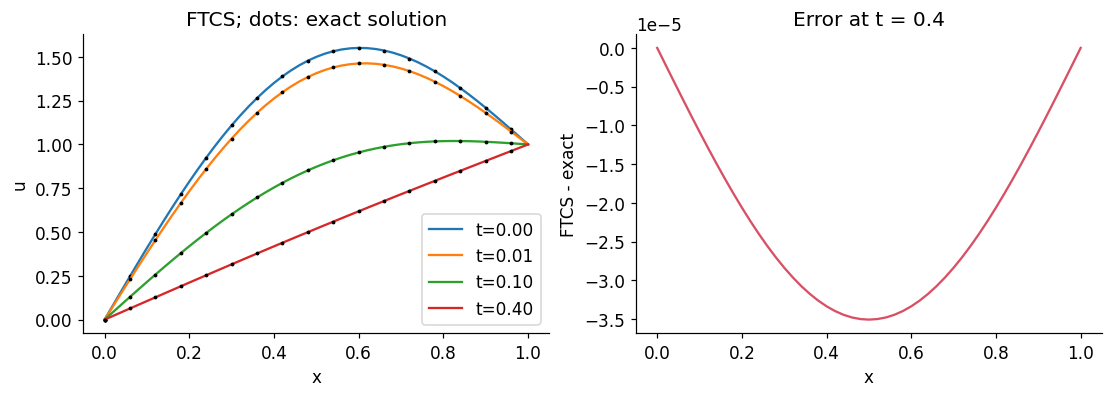

r = 0.400000; final maximum error = 3.508e-05


In [3]:
x, times, states, r = solve_heat()
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), layout="constrained")
for t in [0, 0.01, 0.1, 0.4]:
    index = np.argmin(abs(times - t))
    axes[0].plot(x, states[index], label=f"t={times[index]:.2f}")
    axes[0].plot(x[::3], exact_solution(x[::3], times[index]), "k.", ms=3)
axes[0].set(xlabel="x", ylabel="u", title="FTCS; dots: exact solution")
axes[0].legend()
axes[1].plot(x, states[-1] - exact_solution(x, times[-1]), color=red)
axes[1].set(xlabel="x", ylabel="FTCS - exact", title="Error at t = 0.4")
plt.show()
print(f"r = {r:.6f}; final maximum error = {np.max(abs(states[-1]-exact_solution(x, .4))):.3e}")

## Уточнение сетки / 网格加密
Сравниваем ошибки в один момент времени t = 0.4. При фиксированном r время и пространство уточняются вместе.
在同一时刻比较误差，保持 r 不变，同时减小空间步长和时间步长。

nx: [26, 51, 101]
Maximum errors: [np.float64(0.00013999125603370022), np.float64(3.508166488486175e-05), np.float64(8.771327974277376e-06)]
Observed orders: [1.9965476  1.99985003]


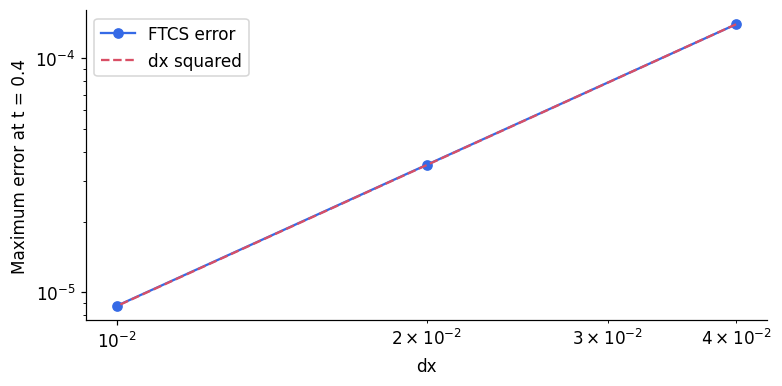

In [4]:
sizes = [26, 51, 101]
errors, steps = [], []
for nx in sizes:
    grid, tgrid, solution, ratio = solve_heat(nx)
    steps.append(grid[1] - grid[0])
    errors.append(np.max(abs(solution[-1] - exact_solution(grid, tgrid[-1]))))
orders = np.log2(np.array(errors[:-1]) / np.array(errors[1:]))
print("nx:", sizes)
print("Maximum errors:", errors)
print("Observed orders:", orders)
fig, ax = plt.subplots(figsize=(7, 3.4), layout="constrained")
ax.loglog(steps, errors, "o-", color=blue, label="FTCS error")
ax.loglog(steps, errors[0]*(np.asarray(steps)/steps[0])**2, "--", color=red, label="dx squared")
ax.set(xlabel="dx", ylabel="Maximum error at t = 0.4")
ax.legend()
plt.show()